#Exploratory Data Analysis

This dataset is composed by 5000 CVs...

In [1]:
!pip3 install pandas
!pip install adjustText

In [65]:
import json
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.decomposition import PCA
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from adjustText import adjust_text
import networkx as nx
import shutil
import os

In [3]:

import json
import pandas as pd

def readfiles(raw_data_path):
    raw_path = Path(raw_data_path)
    texts = []
    annotations_ = []

    for json_file in raw_path.rglob("*.json"):
        with open(json_file, 'r', encoding='utf-8', errors='replace') as f:
            data = json.load(f)
            
            text = data.get("text", "")
            
            # Clean lone surrogates that crash PyArrow/Pandas
            if isinstance(text, str):
                text = text.encode("utf-8", "surrogatepass").decode("utf-8", "ignore")
            
            annotations = data.get("annotations", [])

            texts.append(text)
            annotations_.append(annotations)
            
    df_skills = pd.DataFrame({"text": texts, "annotations": annotations_})
    return df_skills

In [4]:
df_skills = readfiles("data/raw")

In [5]:
df_skills.head()

,text,annotations
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL..."
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ..."
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK..."
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI..."
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI..."


In [6]:
df_skills["annotations"][0:2].tolist()

[[[657, 665, 'SKILL: Building'],
  [822, 828, 'SKILL: python'],
  [811, 815, 'SKILL: java'],
  [781, 790, 'SKILL: Knowledge'],
  [877, 887, 'SKILL: Processing'],
  [194, 205, 'SKILL: performance'],
  [442, 452, 'SKILL: Technology'],
  [1007, 1014, 'SKILL: PySpark'],
  [30, 44, 'SKILL: Data Scientist'],
  [153, 162, 'SKILL: Detection'],
  [329, 345, 'SKILL: computer science'],
  [102, 108, 'SKILL: Images'],
  [889, 902, 'SKILL: Deep Learning'],
  [942, 954, 'SKILL: data science'],
  [1031, 1037, 'SKILL: skills'],
  [1147, 1155, 'SKILL: Projects'],
  [734, 737, 'SKILL: CAN'],
  [575, 590, 'SKILL: Market Research'],
  [956, 969, 'SKILL: Data Analysis'],
  [904, 919, 'SKILL: Computer Vision'],
  [802, 809, 'SKILL: Process'],
  [817, 818, 'SKILL: C'],
  [164, 167, 'SKILL: OCR'],
  [604, 612, 'SKILL: Analysis'],
  [838, 846, 'SKILL: Learning'],
  [971, 988, 'SKILL: Software Engineer'],
  [338, 345, 'SKILL: Science'],
  [267, 278, 'SKILL: Probability'],
  [772, 780, 'SKILL: Exchange'],
  [379

In [7]:
def extract_skills(annotation_list):
    # This list comprehension pulls the string from index 2 of each sub-list
    return [item[2] for item in annotation_list]

# Create the new column
df_skills['skills_list'] = df_skills['annotations'].apply(extract_skills)

# Optional: If you want a single string separated by commas instead of a list:
# df_skills['skills_string'] = df_skills['skills_list'].apply(lambda x: ", ".join(x))

In [8]:
#Remover vazios
df_skills = df_skills[df_skills['skills_list'].apply(len) > 0].copy()

df_skills = df_skills.reset_index(drop=True)

print(f"Novo total de CVs: {len(df_skills)}")
print(df_skills.head())

Novo total de CVs: 4971
                                                text  \
0  One97 Communications Limited \nData Scientist ...   
1  Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...   
2  Yogesh Chandra Pandey Mobile: +91--7017692645\...   
3  ARUN KUMAR U.C.  \n \nMob :+91 9745004628     ...   
4  ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...   

                                         annotations  \
0  [[657, 665, SKILL: Building], [822, 828, SKILL...   
1  [[383, 389, SKILL: scikit], [338, 344, SKILL: ...   
2  [[298, 307, SKILL: reporting], [1218, 1234, SK...   
3  [[415, 425, SKILL: WINDOWS XP], [709, 724, SKI...   
4  [[1089, 1099, SKILL: Test cases], [61, 66, SKI...   

                                         skills_list  
0  [SKILL: Building, SKILL: python, SKILL: java, ...  
1  [SKILL: scikit, SKILL: python, SKILL: Scikit l...  
2  [SKILL: reporting, SKILL: Business Studies, SK...  
3  [SKILL: WINDOWS XP, SKILL: Problem solving, SK...  
4  [SKILL: Test cases, SKIL

In [9]:
df_skills.head()


,text,annotations,skills_list
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL...","[SKILL: Building, SKILL: python, SKILL: java, ..."
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ...","[SKILL: scikit, SKILL: python, SKILL: Scikit l..."
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[SKILL: reporting, SKILL: Business Studies, SK..."
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI...","[SKILL: WINDOWS XP, SKILL: Problem solving, SK..."
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[SKILL: Test cases, SKILL: GMail, SKILL: java,..."


In [10]:
df_skills["skills_list"][0]

['SKILL: Building',
 'SKILL: python',
 'SKILL: java',
 'SKILL: Knowledge',
 'SKILL: Processing',
 'SKILL: performance',
 'SKILL: Technology',
 'SKILL: PySpark',
 'SKILL: Data Scientist',
 'SKILL: Detection',
 'SKILL: computer science',
 'SKILL: Images',
 'SKILL: Deep Learning',
 'SKILL: data science',
 'SKILL: skills',
 'SKILL: Projects',
 'SKILL: CAN',
 'SKILL: Market Research',
 'SKILL: Data Analysis',
 'SKILL: Computer Vision',
 'SKILL: Process',
 'SKILL: C',
 'SKILL: OCR',
 'SKILL: Analysis',
 'SKILL: Learning',
 'SKILL: Software Engineer',
 'SKILL: Science',
 'SKILL: Probability',
 'SKILL: Exchange',
 'SKILL: M',
 'SKILL: vision',
 'SKILL: Communications',
 'SKILL: Language Processing',
 'SKILL: Team',
 'SKILL: Data',
 'SKILL: Natural Language Processing',
 'SKILL: Engineer',
 'SKILL: Object detection',
 'SKILL: Pattern',
 'SKILL: Computer Science Engineering',
 'SKILL: machine learning',
 'SKILL: Kubeflow',
 'SKILL: Research',
 'SKILL: Patterns',
 'SKILL: Premium',
 'SKILL: Probl

In [11]:
df_skills["num_annon"]=df_skills["skills_list"].apply(len)

<Axes: >

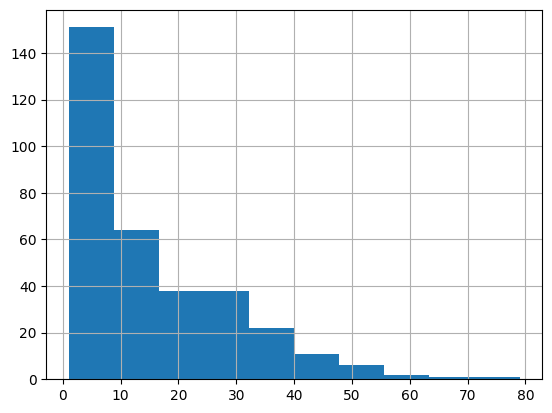

In [12]:
df_skills["num_annon"].value_counts().hist()

#Há uma tendência para os currículso terem, em média, 10 annotações.

In [13]:
df_skills["skills_list"]

0       [SKILL: Building, SKILL: python, SKILL: java, ...
1       [SKILL: scikit, SKILL: python, SKILL: Scikit l...
2       [SKILL: reporting, SKILL: Business Studies, SK...
3       [SKILL: WINDOWS XP, SKILL: Problem solving, SK...
4       [SKILL: Test cases, SKILL: GMail, SKILL: java,...
                              ...                        
4966    [SKILL: Sensor, SKILL: Music, SKILL: Advertisi...
4967    [SKILL: ADAM, SKILL: CAN, SKILL: Advertising, ...
4968    [SKILL: Reports, SKILL: VMware, SKILL: Typing,...
4969    [SKILL: Inventory, SKILL: GMail, SKILL: Knowle...
4970    [SKILL: Debugging skills, SKILL: Ability, SKIL...
Name: skills_list, Length: 4971, dtype: object

In [14]:
unique_skills = df_skills["skills_list"].explode().unique().tolist()

In [15]:
len(unique_skills)

12695

In [16]:
skill_counts = df_skills["skills_list"].apply(set).explode().value_counts()

print(skill_counts)

skills_list
SKILL: COM                   3874
SKILL: skills                3805
SKILL: Work                  3679
SKILL: Personal              3458
SKILL: Knowledge             3417
                             ... 
SKILL: Emergency Medicine       1
SKILL: Clinical problems        1
SKILL: iHeart Radio             1
SKILL: Big Bang                 1
SKILL: Debugging skills         1
Name: count, Length: 12695, dtype: int64


<Axes: xlabel='skills_list'>

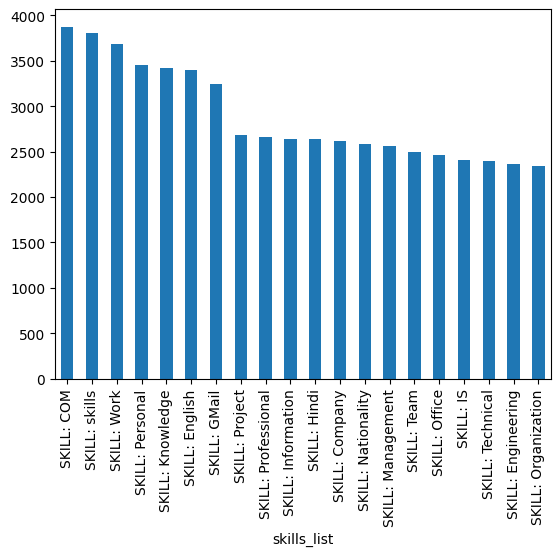

In [17]:
skill_counts.head(20).plot(kind='bar')

In [18]:
df_skills

,text,annotations,skills_list,num_annon
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL...","[SKILL: Building, SKILL: python, SKILL: java, ...",70
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ...","[SKILL: scikit, SKILL: python, SKILL: Scikit l...",32
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[SKILL: reporting, SKILL: Business Studies, SK...",52
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI...","[SKILL: WINDOWS XP, SKILL: Problem solving, SK...",42
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[SKILL: Test cases, SKILL: GMail, SKILL: java,...",80
...,...,...,...,...
4966,"\t\n\t\n\t\n\t\n \nDestinee Handly, Manicurist...","[[1283, 1289, SKILL: Sensor], [1305, 1310, SKI...","[SKILL: Sensor, SKILL: Music, SKILL: Advertisi...",12
4967,"\t\n\t\n\t\n \nDevon Nuszer, Wardrobe Stylist...","[[207, 211, SKILL: ADAM], [755, 758, SKILL: CA...","[SKILL: ADAM, SKILL: CAN, SKILL: Advertising, ...",8
4968,RESUME\nName :Gaurav Dwivedi\nAge :27 Years\nD...,"[[2070, 2077, SKILL: Reports], [2399, 2405, SK...","[SKILL: Reports, SKILL: VMware, SKILL: Typing,...",72
4969,ResumeNitesh\nNITESH KUMAR\n Email id: niteshj...,"[[1876, 1885, SKILL: Inventory], [73, 78, SKIL...","[SKILL: Inventory, SKILL: GMail, SKILL: Knowle...",89


In [19]:
df_skills[df_skills["skills_list"].apply(lambda x: "SKILL: COM" in x)]

,text,annotations,skills_list,num_annon
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[SKILL: reporting, SKILL: Business Studies, SK...",52
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[SKILL: Test cases, SKILL: GMail, SKILL: java,...",80
6,"\t\n\t\n\t\n\t\n\t\n\t\nBarbara Farman, Hair,...","[[787, 793, SKILL: Hunter], [1618, 1624, SKILL...","[SKILL: Hunter, SKILL: Health, SKILL: ADAMS, S...",36
7,"\n2632 La Cienega Avenue Los Angeles, C...","[[847, 853, SKILL: Hunter], [2447, 2451, SKILL...","[SKILL: Hunter, SKILL: COLA, SKILL: Australia,...",23
8,"\n \n \n \nBethany Newell, Manicurist \nwww.c...","[[968, 980, SKILL: Self service], [1799, 1805,...","[SKILL: Self service, SKILL: Forbes, SKILL: co...",21
...,...,...,...,...
4965,"\n \n \n \nDenika Bedrossian , Makeup Artist...","[[105, 109, SKILL: ADAM], [3504, 3512, SKILL: ...","[SKILL: ADAM, SKILL: Big Bang, SKILL: CAN, SKI...",38
4966,"\t\n\t\n\t\n\t\n \nDestinee Handly, Manicurist...","[[1283, 1289, SKILL: Sensor], [1305, 1310, SKI...","[SKILL: Sensor, SKILL: Music, SKILL: Advertisi...",12
4967,"\t\n\t\n\t\n \nDevon Nuszer, Wardrobe Stylist...","[[207, 211, SKILL: ADAM], [755, 758, SKILL: CA...","[SKILL: ADAM, SKILL: CAN, SKILL: Advertising, ...",8
4969,ResumeNitesh\nNITESH KUMAR\n Email id: niteshj...,"[[1876, 1885, SKILL: Inventory], [73, 78, SKIL...","[SKILL: Inventory, SKILL: GMail, SKILL: Knowle...",89


In [20]:
x=df_skills[df_skills["skills_list"].apply(lambda x: "SKILL: COM" in x)]
[ano for ano in x["annotations"].iloc[0] if "SKILL: COM" in ano]


[[103, 106, 'SKILL: COM']]

In [21]:
df_skills["text"][2][95:120]

'y@yahoo.com\nSummary\nProfi'

In [22]:
#Remover Prefixo "Skill"

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda x: [item.split(': ')[-1] if ': ' in item else item for item in x]
)

In [23]:
df_skills.head()

,text,annotations,skills_list,num_annon
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL...","[Building, python, java, Knowledge, Processing...",70
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ...","[scikit, python, Scikit learn, TensorFlow, Dee...",32
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[reporting, Business Studies, Managing, Maths,...",52
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI...","[WINDOWS XP, Problem solving, Knowledge, Arts,...",42
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[Test cases, GMail, java, Knowledge, ASP, Crit...",80


In [24]:
df_skills["skills_list"].explode().value_counts()

skills_list
COM                             3874
skills                          3805
Work                            3679
Personal                        3458
Knowledge                       3417
                                ... 
Research Programs                  1
Continuing Medical Education       1
Big Bang                           1
iHeart Radio                       1
Debugging skills                   1
Name: count, Length: 12693, dtype: int64

In [25]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)

def clean_skills_text(skills_list):
    stop_words = set(stopwords.words('english'))
    cleaned_list = []
    for skill in skills_list:

        words = skill.split()
        filtered_words = [w for w in words if w.lower() not in stop_words]
        cleaned_skill = " ".join(filtered_words).strip()
        if cleaned_skill:
            cleaned_list.append(cleaned_skill)
            
    return cleaned_list

df_skills['skills_list'] = df_skills['skills_list'].apply(clean_skills_text)

df_skills['skills_list'] = df_skills['skills_list'].apply(lambda x: list(set(x)))

In [26]:
#Remover skills genéricas e não relevantes
blacklist = {"COM", "Skills" , "personal","information", "knowledge", "process", "skills", "can", "work", "marital status", "nationality", "com", "languages", "board", "email", "qualification","activities"}

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda lista: [s for s in lista if s.lower() not in blacklist]
)


In [27]:
#Colocar em minusculas

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda lista: list(set([s.lower().strip() for s in lista]))
)

print(df_skills['skills_list'].head())

df_skills["skills_list"].explode().count()

0    [performance, space, data science, team, insig...
1    [matplotlib, company, tensorflow, smart, sciki...
2    [meetings, handling, team, salary, mobile, com...
3    [history, company, team, bachelor arts, window...
4    [reviewing, team, system testing, operational,...
Name: skills_list, dtype: object


np.int64(493902)

skills_list
english              3399
gmail                3238
project              2683
professional         2661
hindi                2636
                     ... 
clinical teams          1
research programs       1
big bang                1
iheart radio            1
debugging skills        1
Name: count, Length: 12569, dtype: int64


Text(0.5, 0, 'Skills names')

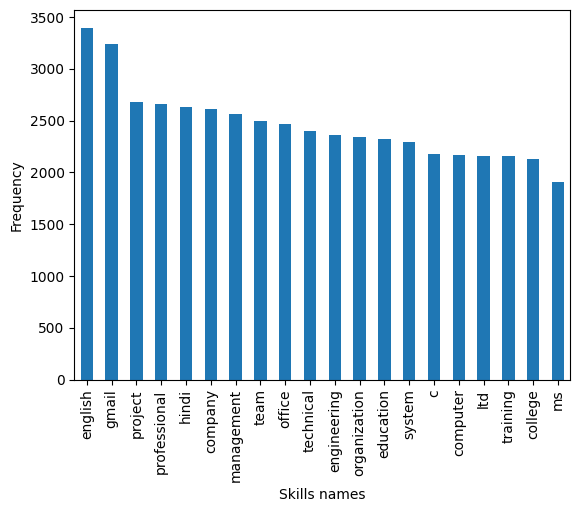

In [45]:
skill_counts = df_skills["skills_list"].apply(set).explode().value_counts()

print(skill_counts)

skill_counts.head(20).plot(kind='bar')
plt.ylabel('Frequency')
plt.xlabel('Skills names')
#Removemos conectores(e.g "is") e outras skills que não eram relevantes"

Quantas skills por CV

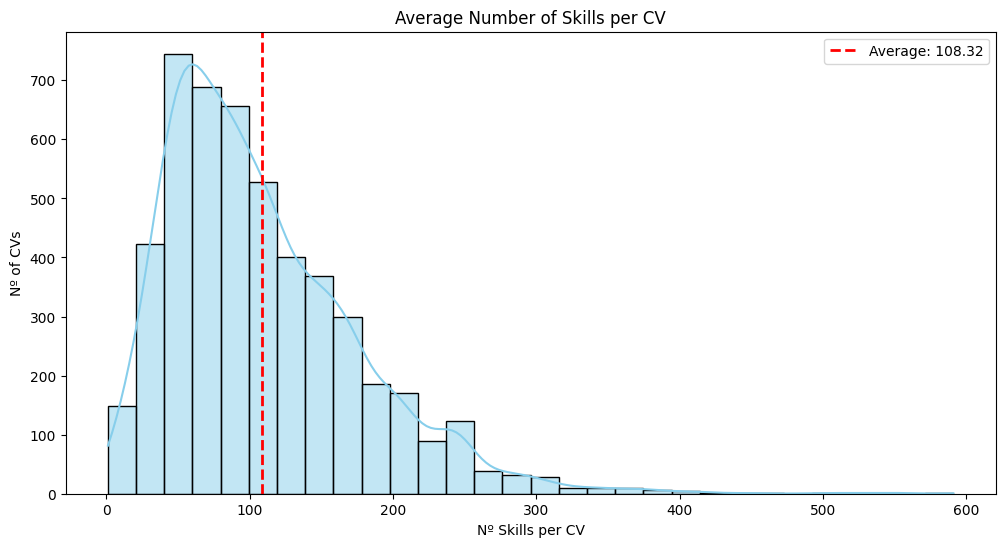

In [43]:

media_skills = df_skills['num_annon'].mean()

plt.figure(figsize=(12, 6))
sns.histplot(df_skills['num_annon'], bins=30, kde=True, color='skyblue')
plt.axvline(media_skills, color='red', linestyle='--', linewidth=2, label=f'Average: {media_skills:.2f}')

plt.title('Average Number of Skills per CV')
plt.xlabel('Nº Skills per CV')
plt.ylabel('Nº of CVs')
plt.legend()
plt.show()

Será que existem skills relacionadas?

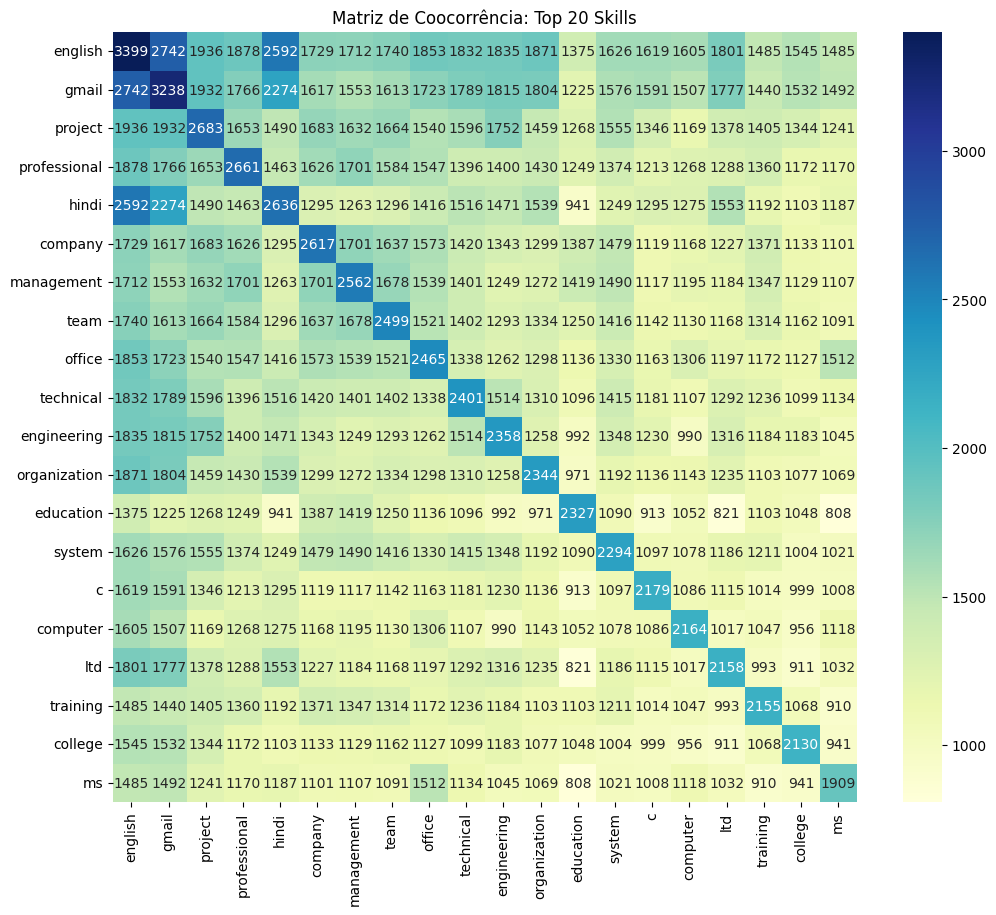

In [30]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
skills_encoded = pd.DataFrame(mlb.fit_transform(df_skills['skills_list']), 
                             columns=mlb.classes_, 
                             index=df_skills.index)

top_20_skills = df_skills['skills_list'].explode().value_counts().head(20).index
subset_encoded = skills_encoded[top_20_skills]

co_occurrence_matrix = subset_encoded.T.dot(subset_encoded)

plt.figure(figsize=(12, 10))
sns.heatmap(co_occurrence_matrix, annot=True, fmt="d", cmap="YlGnBu")
plt.title('Matriz de Coocorrência: Top 20 Skills')
plt.show()

E quais são as mais raras?

In [59]:
individual = df_skills['skills_list'].explode().value_counts()
total= df_skills['skills_list'].explode().count()
individual_pct = (individual / total) * 100

skills_stats = pd.DataFrame({
    'contagem': individual,
    'percentagem': individual_pct
})

limite_raridade = 0.15
skills_raras = skills_stats[skills_stats['percentagem'] < limite_raridade]

print(f"Total de skills únicas: {len(individual)}")
print(f"Total de skills raras (<{limite_raridade}%): {len(skills_raras)}")
print(f"Total de skills restantes (>={limite_raridade}%): {len(individual) - len(skills_raras)}")
print("\nExemplos de Skills Raras:")
print(skills_raras.tail(30))

Total de skills únicas: 12569
Total de skills raras (<0.15%): 12449
Total de skills restantes (>=0.15%): 120

Exemplos de Skills Raras:
                              contagem  percentagem
skills_list                                        
capital iq                           1     0.000202
cash flow modeling                   1     0.000202
credit review                        1     0.000202
legal assistance                     1     0.000202
law degree                           1     0.000202
correspondence preparation           1     0.000202
client focus                         1     0.000202
oid                                  1     0.000202
bain                                 1     0.000202
independent decision making          1     0.000202
advanced research                    1     0.000202
language fluency                     1     0.000202
medical imaging                      1     0.000202
pharmacovigilance                    1     0.000202
emergency medicine              

In [32]:
counts = df_skills['skills_list'].explode().value_counts()
total_val = df_skills['skills_list'].explode().count()

individual_pct = (counts / total_val) * 100
print(total_val)

493902


In [33]:
counts = df_skills['skills_list'].explode().value_counts()
print(counts.sum())

493902


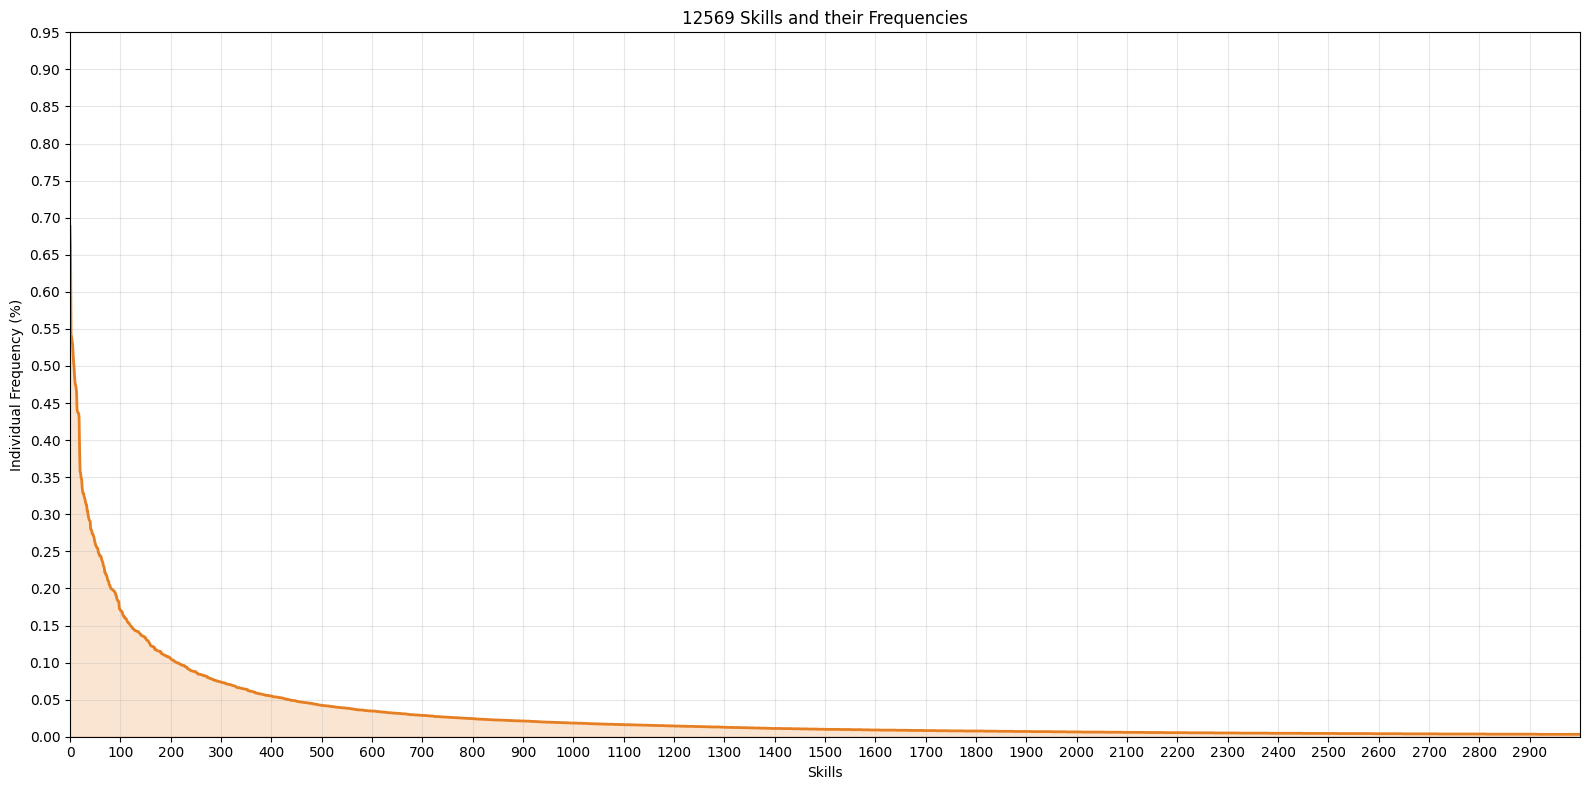

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

individual = df_skills['skills_list'].explode().value_counts()
total= df_skills['skills_list'].explode().count()
individual_pct = (individual / total) * 100

y_values = individual_pct.values
x_values = np.arange(len(y_values))

plt.figure(figsize=(16, 8))
plt.plot(x_values, y_values, color='#e67e22', linewidth=2)
plt.fill_between(x_values, y_values, color='#e67e22', alpha=0.2)

plt.xlabel('Skills')
plt.ylabel('Individual Frequency (%)')
plt.title(f'{len(y_values)} Skills and their Frequencies')

plt.xlim(0, 3000)
plt.xticks(np.arange(0, 3000, 100))
plt.grid(True, axis='both', ls="-", alpha=0.3)

if len(y_values) > 0:
    plt.ylim(0, y_values.max() * 1.1)
    plt.yticks(np.arange(0, 1, 0.05))
plt.tight_layout()
plt.show()

Vamos remover as mais raras (menos de 0.01%)

In [66]:
#Passar as mais raras (<0.01%) para outra pasta

individual = df_skills['skills_list'].explode().value_counts()
total= df_skills['skills_list'].explode().count()
individual_pct = (individual / total) * 100

skills_validas = set(individual_pct[individual_pct >= 0.01].index)

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda lista: [skill for skill in lista if skill in skills_validas]
)

df_skills = df_skills[df_skills['skills_list'].apply(len) > 0].copy()

output_dir = 'data/processed/frequency_adjusted'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

df_skills.to_csv(os.path.join(output_dir, 'df_skills_limpo.csv'), index=False)

Vamos agrupar por skills que aparecem nos mesmo CVs e depois por tipos de cvs

Grupos de skills que aparecem nos mesmo CVs

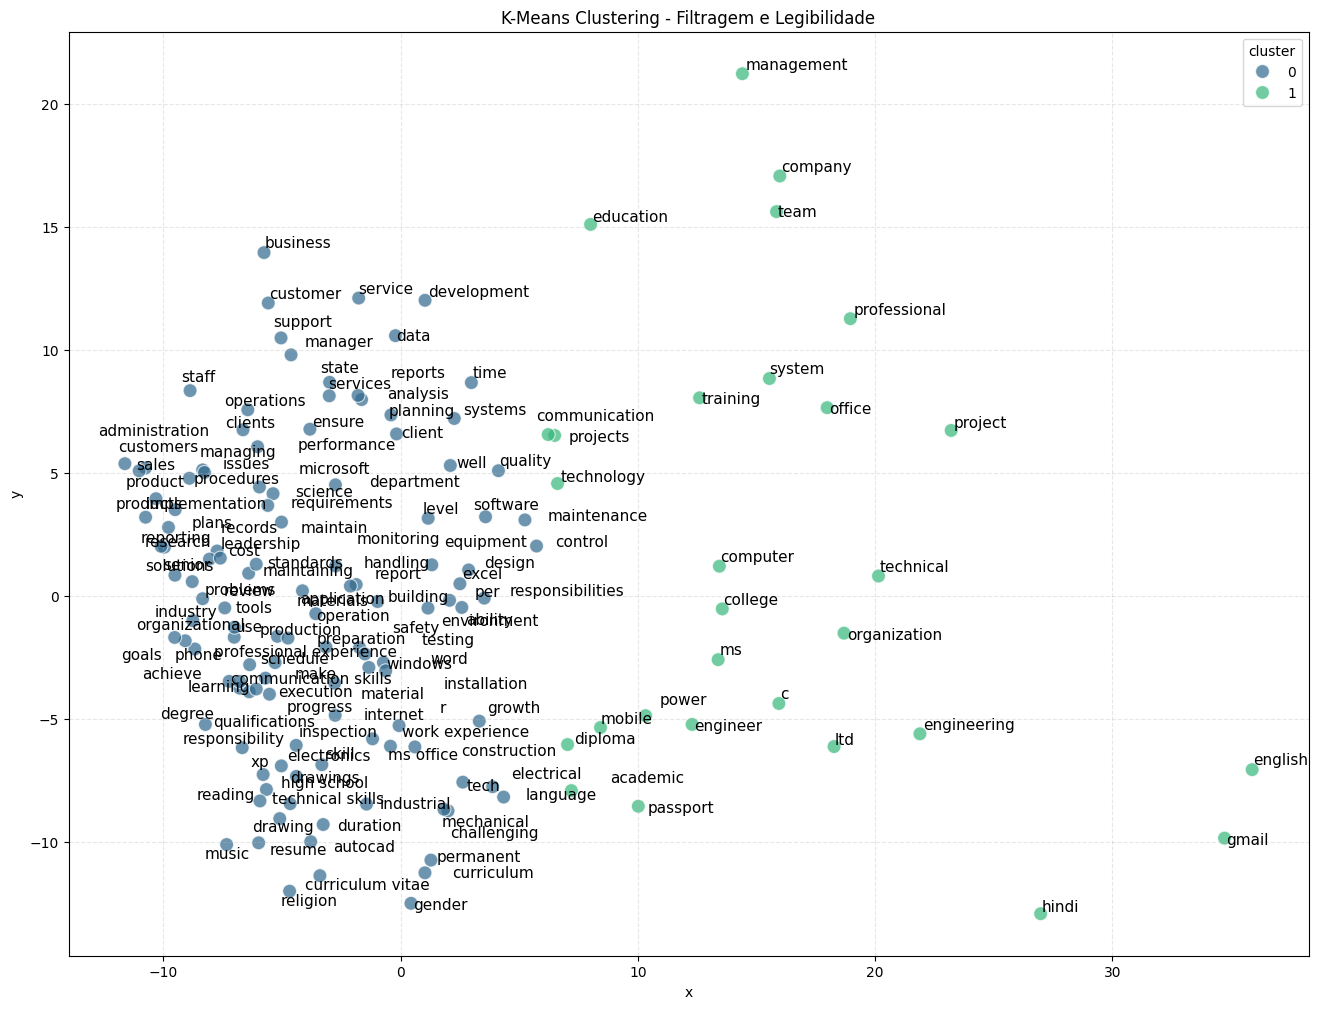

In [ ]:
#Professor: Limite a 150 skills porque se não é ilegível. Fiz com vários grupos mas visualmente só acho relevante 2/3

mlb = MultiLabelBinarizer()
skills_matrix = pd.DataFrame(mlb.fit_transform(df_skills['skills_list']), columns=mlb.classes_)

min_occurrence = 50 
frequent_skills = skills_matrix.columns[skills_matrix.sum() > min_occurrence]

if len(frequent_skills) > 150:
    frequent_skills = skills_matrix.sum().sort_values(ascending=False).head(150).index

matrix_to_cluster = skills_matrix[frequent_skills].T

n_clusters = 2
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clusters = kmeans.fit_predict(matrix_to_cluster)

pca = PCA(n_components=2)
reduced_data = pca.fit_transform(matrix_to_cluster)

plt.figure(figsize=(16, 12))
scatter_df = pd.DataFrame({
    'x': reduced_data[:, 0],
    'y': reduced_data[:, 1],
    'label': frequent_skills,
    'cluster': clusters
})

sns.scatterplot(data=scatter_df, x='x', y='y', hue='cluster', palette='viridis', s=100, alpha=0.7)

texts = []
for i in range(len(scatter_df)):
    texts.append(plt.text(scatter_df.x[i], scatter_df.y[i], scatter_df.label[i], fontsize=11))

adjust_text(texts, force_points=0.2, force_text=0.2, expand_points=(1.2, 1.2))

plt.title('K-Means Clustering - Filtragem e Legibilidade')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

Tipos de perfis de acordo com as palavras principais/iniciais

Perfil 0: management, systems, data, system, support, microsoft, technology, software, network, security
Perfil 1: management, business, customer, development, skills, team, communication, service, office, financial
Perfil 2: data, learning, analysis, science, software, development, sql, analytics, machine, language
Perfil 3: project, electrical, engineering, management, maintenance, technical, engineer, quality, safety, control
Perfil 4: skills, english, gmail, computer, ms, communication, office, hindi, technical, engineering


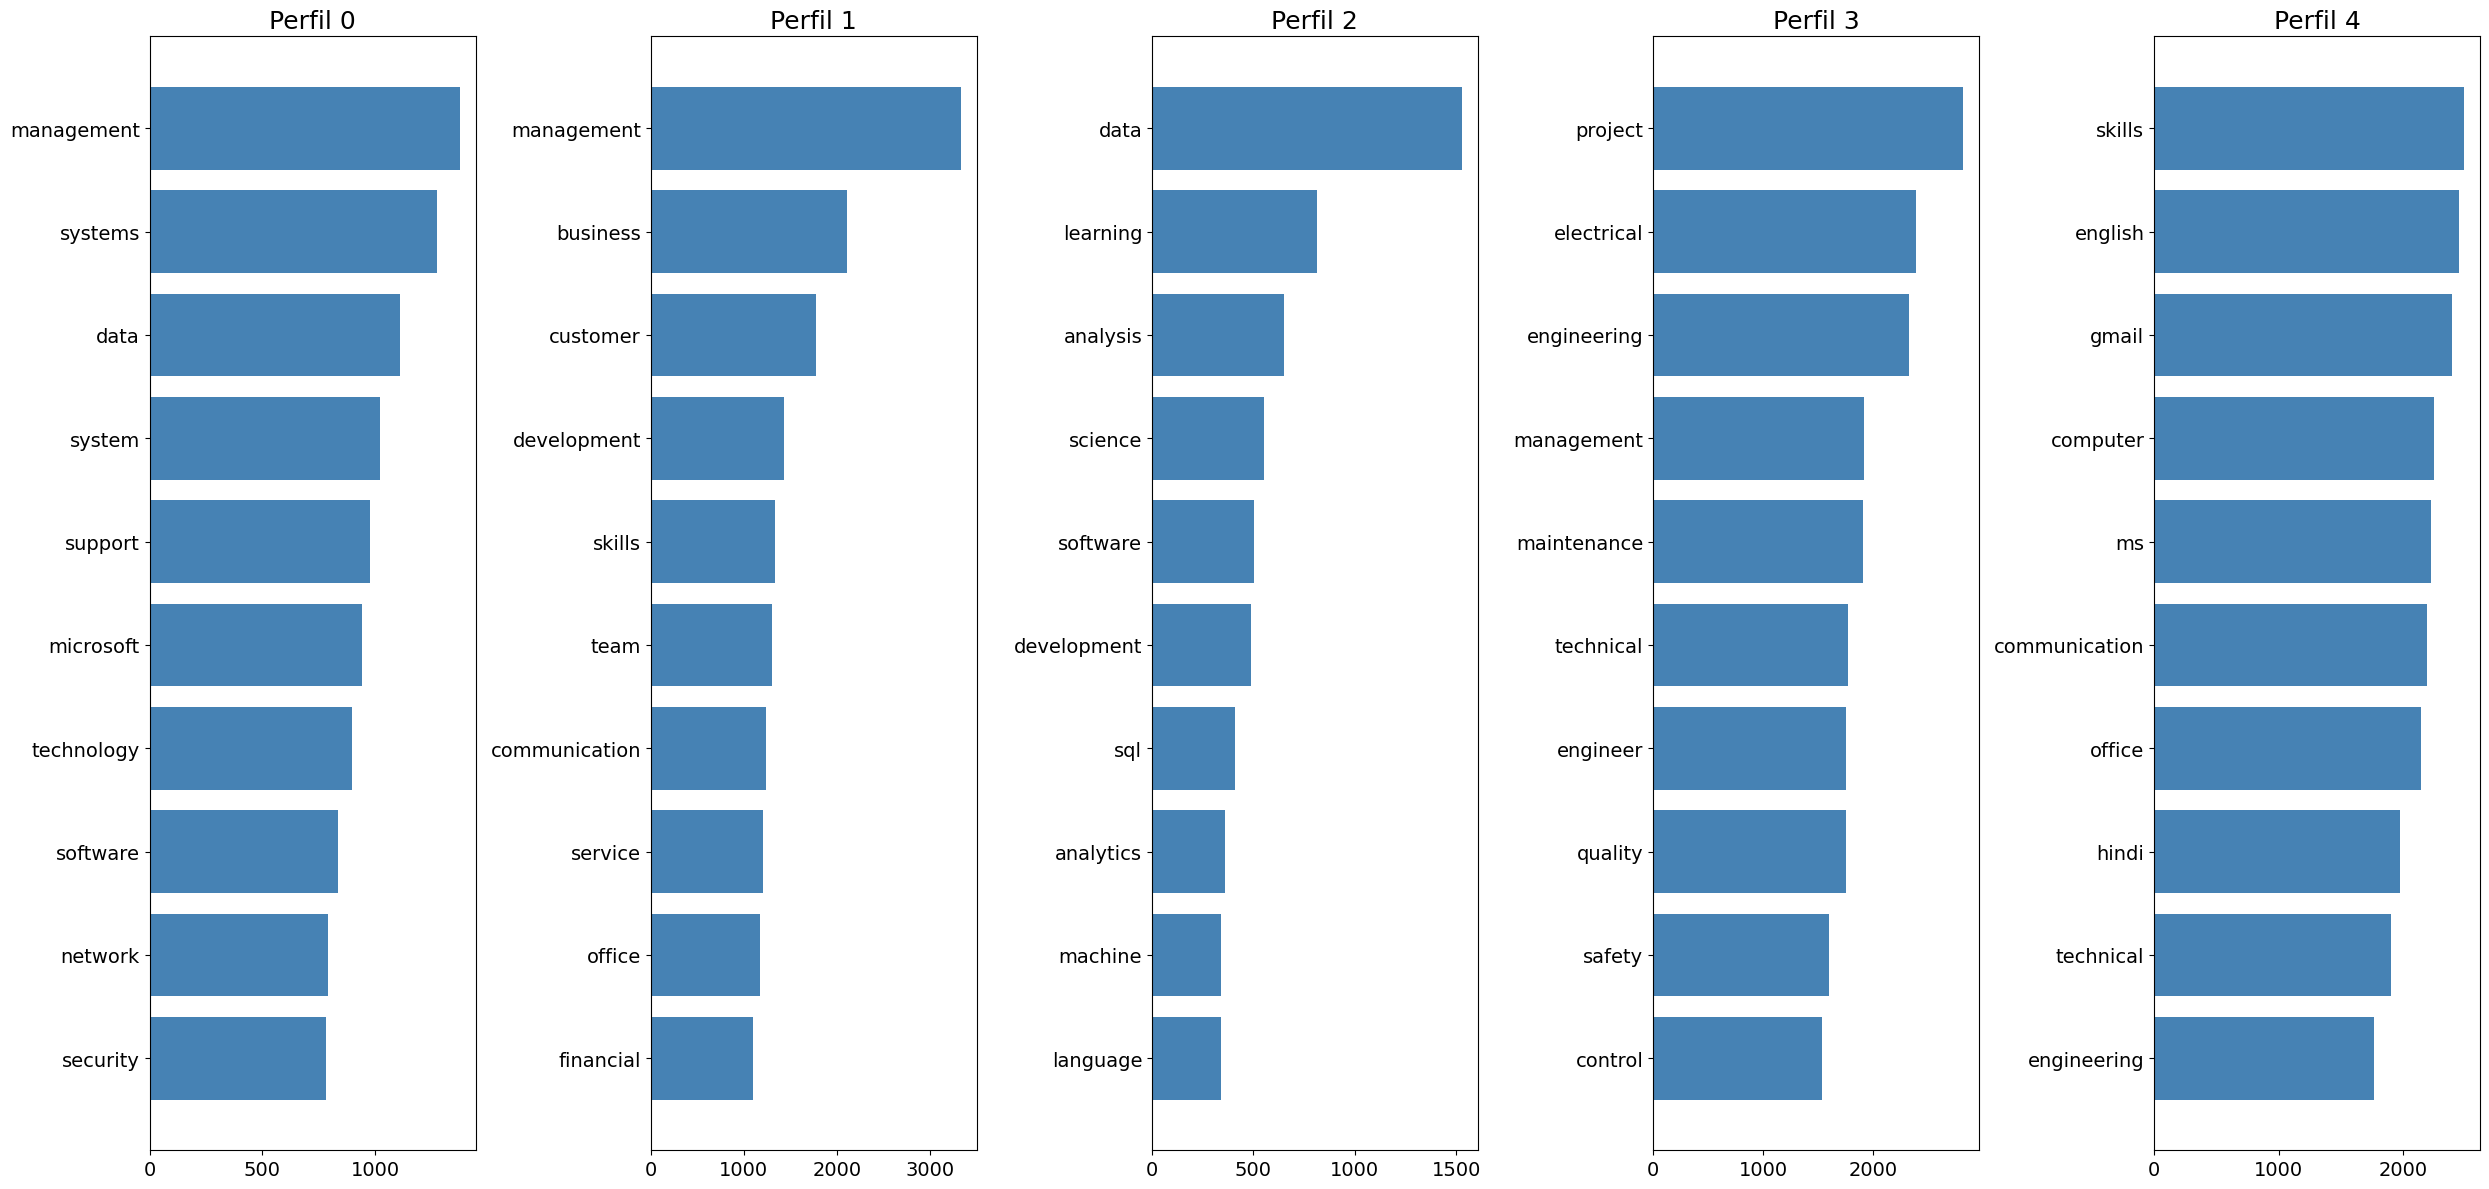

In [ ]:
skills_as_sentences = df_skills['skills_list'].apply(lambda x: " ".join(x))
vectorizer = CountVectorizer()
doc_term_matrix = vectorizer.fit_transform(skills_as_sentences)

n_topics = 5
lda = LatentDirichletAllocation(n_components=n_topics, random_state=42)
lda.fit(doc_term_matrix)

words = vectorizer.get_feature_names_out()
fig, axes = plt.subplots(1, n_topics, figsize=(25, 12), sharex=False)
axes = axes.flatten()

for topic_idx, topic in enumerate(lda.components_):
    top_features_ind = topic.argsort()[:-11:-1]
    top_features = [words[i] for i in top_features_ind]
    weights = topic[top_features_ind]

    ax = axes[topic_idx]
    ax.barh(top_features, weights, color='steelblue')
    ax.set_title(f'Perfil {topic_idx}', fontdict={'fontsize': 18})
    ax.invert_yaxis()
    ax.tick_params(axis='both', which='major', labelsize=14)

plt.tight_layout()
plt.savefig('lda_viz.png')

for topic_idx, topic in enumerate(lda.components_):
    top_words = [words[i] for i in topic.argsort()[:-11:-1]]
    print(f"Perfil {topic_idx}: {', '.join(top_words)}")